# Timeseries — Peramalan dengan Variabel Eksogen (SARIMAX)
**Kapan dipakai:** target dipengaruhi deret lain yang nilainya **diketahui untuk periode
ramalan** (harga BBM, jadwal promo, libur, suhu ramalan BMKG).

**Langkah:** split waktu → SARIMAX dengan `exog=` → bandingkan dengan naive (nilai terakhir).
Catatan: uji memakai nilai eksogen aktual periode uji. Di lomba, pastikan nilai eksogen masa
depan tersedia; kalau tidak, ramal dulu eksogennya atau pakai `peramalan_statistik`.

**Data demo:** PDB riil AS kuartalan (`realgdp`) dengan eksogen `unemp`, `tbilrate`, `realinv`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
from sklearn.metrics import root_mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/timeseries/forecasting"   # GANTI saat lomba
SERIES_CSV = f"{DATA_FOLDER}/macro_quarterly.csv"

DATE_COL = "date"
TARGET = "realgdp"
EXOG_COLS = ["unemp", "tbilrate", "realinv"]
FREQUENCY = "QS"      # QS = kuartalan, MS = bulanan, D = harian
SEASON_LENGTH = 4     # musim kuartalan
HORIZON = 8           # jumlah langkah ramalan (8 kuartal = 2 tahun)

## Baca data dan EDA

In [3]:
table = pd.read_csv(SERIES_CSV, parse_dates=[DATE_COL], index_col=DATE_COL)
table = table.asfreq(FREQUENCY)
missing = table.isna().sum()
print(table.shape, "| missing:", missing.sum())
table.head()

(203, 6) | missing: 0


,realgdp,realcons,realinv,unemp,tbilrate,infl
date,,,,,,
1959-01-01,2710.349,1707.4,286.898,5.8,2.82,0.00
1959-04-01,2778.801,1733.7,310.859,5.1,3.08,2.34
1959-07-01,2775.488,1751.8,289.226,5.3,3.82,2.74
1959-10-01,2785.204,1753.7,299.356,5.6,4.33,0.27
1960-01-01,2847.699,1770.5,331.722,5.2,3.50,2.31


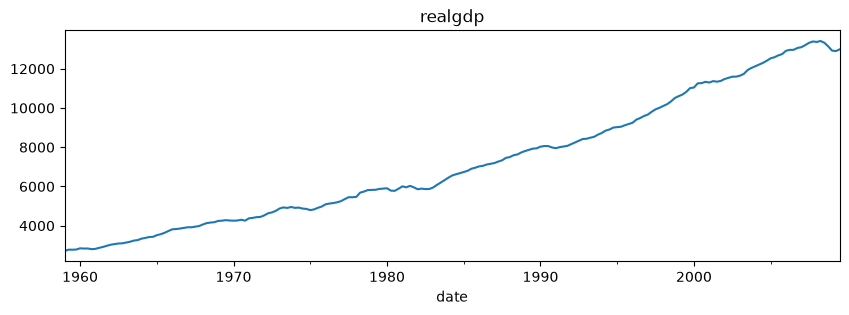

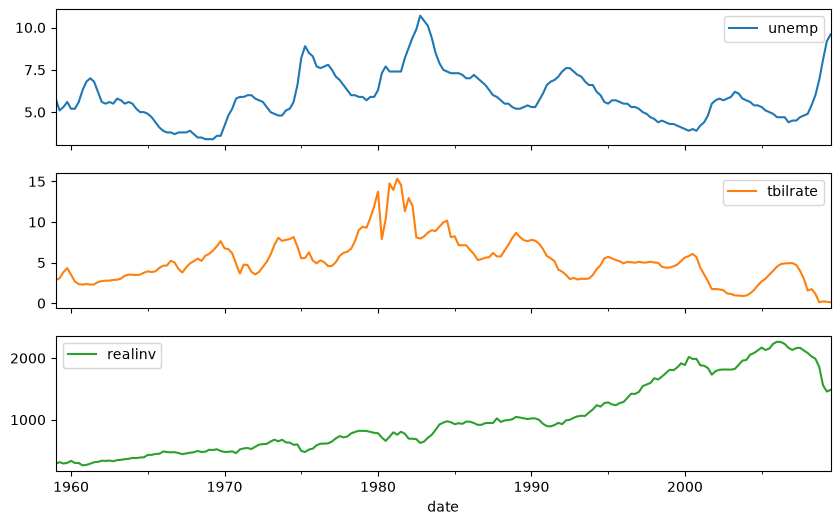

In [4]:
table[TARGET].plot(figsize=(10, 3), title=TARGET)
plt.show()
table[EXOG_COLS].plot(subplots=True, figsize=(10, 6))
plt.show()

## Split waktu (bukan acak)

In [5]:
y = table[TARGET]
X = table[EXOG_COLS]
y_train = y.iloc[:-HORIZON]
y_test = y.iloc[-HORIZON:]
X_train = X.iloc[:-HORIZON]
X_test = X.iloc[-HORIZON:]
print("latih:", len(y_train), "| uji:", len(y_test))

latih: 195 | uji: 8


## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris aktif.
`order=(p, d, q)`: p = lag AR, d = berapa kali di-differencing, q = lag MA.

In [6]:
def forecast(y_part, X_part, X_future):
    model = SARIMAX(y_part, exog=X_part, order=(1, 1, 1))
    # model = SARIMAX(y_part, exog=X_part, order=(1, 0, 1),
    #                 seasonal_order=(0, 1, 1, SEASON_LENGTH))
    # model = SARIMAX(y_part, exog=X_part, order=(2, 1, 0))
    # model = SARIMAX(y_part, exog=X_part, order=(1, 1, 1), trend="t")
    # model = SARIMAX(y_part, exog=X_part, order=(0, 1, 1))
    fitted = model.fit(disp=False)
    return np.asarray(fitted.forecast(len(X_future), exog=X_future))


print("uji coba 2 langkah:", forecast(y_train, X_train, X_test.iloc[:2]).round(1))

Z:\GEMASTIK-DATABASE\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
Z:\GEMASTIK-DATABASE\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


uji coba 2 langkah: [13348.8 13377.2]


## Evaluasi di data uji (MAE, RMSE, MAPE) dibanding naive

Z:\GEMASTIK-DATABASE\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Z:\GEMASTIK-DATABASE\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\EYZARIM\AppData\Local\Temp\ipykernel_12292\2750522256.py:12: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(y_test.index, predictions, label="ramalan model")


Model SARIMAX MAE: 94.44 | RMSE: 111.34 | MAPE(%): 0.72
Naive         MAE: 192.35 | RMSE: 247.5 | MAPE(%): 1.48


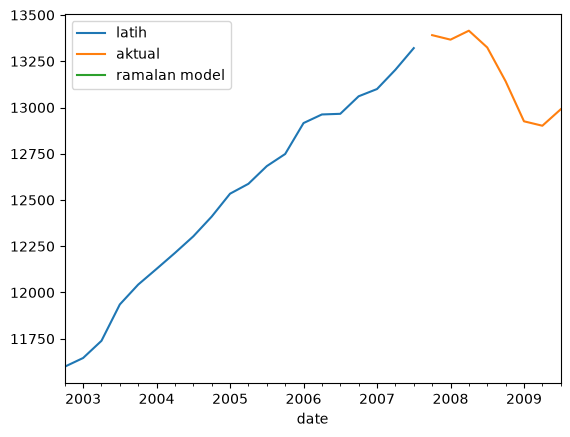

In [7]:
predictions = forecast(y_train, X_train, X_test)
naive = np.repeat(y_train.iloc[-1], HORIZON)       # nilai terakhir diulang
print("Model SARIMAX MAE:", round(mean_absolute_error(y_test, predictions), 2),
      "| RMSE:", round(root_mean_squared_error(y_test, predictions), 2),
      "| MAPE(%):", round(100 * mean_absolute_percentage_error(y_test, predictions), 2))
print("Naive         MAE:", round(mean_absolute_error(y_test, naive), 2),
      "| RMSE:", round(root_mean_squared_error(y_test, naive), 2),
      "| MAPE(%):", round(100 * mean_absolute_percentage_error(y_test, naive), 2))

ax = y_train.iloc[-5 * SEASON_LENGTH:].plot(label="latih")
y_test.plot(ax=ax, label="aktual")
ax.plot(y_test.index, predictions, label="ramalan model")
ax.legend()
plt.show()

## Simpan hasil
Tidak dilatih ulang di semua data: ramalan ke depan butuh nilai eksogen masa depan yang tidak
ada di data demo. Saat lomba: `forecast(y, X, X_future)` dengan `X_future` = tabel eksogen
periode ramalan.

In [8]:
result = pd.DataFrame()
result["tanggal"] = y_test.index
result["aktual"] = y_test.to_numpy()
result["ramalan"] = predictions
result.to_csv("hasil.csv", index=False)
result.head()

,tanggal,aktual,ramalan
0,2007-10-01,13391.249,13348.779997
1,2008-01-01,13366.865,13377.177887
2,2008-04-01,13415.266,13382.051803
3,2008-07-01,13324.600,13398.430051
4,2008-10-01,13141.920,13318.946923
